# House Stage 2: Monte Carlo

Stage 1 (`house.stage1`) gives a point prediction of each district's two-party margin (D − R). Stage 2 turns those into a distribution of outcomes by simulating the errors.

1. **Stage 1 inputs:** the rolling out-of-sample predictions and residuals for 2018–2024, and the 2026 forecast.
2. **Error model:** the structure of the errors and its parameters, estimated from the residuals.
3. **Simulation:** draw errors and add them to the predictions.
4. **Calibration backtest:** simulate every race of each past election, from an error model estimated on earlier years only, and check its calibration.
5. **2026 forecast:** every one of the 435 races, its party win probabilities and predicted candidate, and the seat distribution.

**Race handling** (`src/house/simulation/races.py`). Each race is classified by its general-election lineup before simulation. Only D-vs-R races are simulated from Stage 1 margins. Uncontested races go to their party in every draw, and a major party facing only third parties wins 99.5% of draws (upsets go to the third party). Same-party races (top-two D vs D, R vs R) are their party's seat. Election-rule resolvers (`resolvers.py`) can adjust those outcomes draw by draw; the 2026 forecast uses one, `TopTwoSameParty` (`top_two.py`), which only names the same-party winner (section 5).

Residuals are actual − predicted, in D − R points; positive means Democrats outperformed Stage 1.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# The repository root is the first folder up from here that holds pyproject.toml, so this works at any depth
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))  # for experiments.house
import house.regression as hr

In [2]:
from house import simulation, stage1

CONFIG = stage1.HOUSE_ENSEMBLE_AB_85_15  # the production Stage 1 configuration
FALLBACK_CONFIG = stage1.HOUSE_MODEL_A  # predicts a D-vs-R race CONFIG lacks inputs for
CALIBRATION_CONFIGS = {c.name: c for c in [stage1.HOUSE_MODEL_A, stage1.HOUSE_ENSEMBLE_AB_85_15]}
HOUSE_SEATS = 435

In [3]:
SEED = 42
N_SIMS = 40_000
rng = np.random.default_rng(SEED)

with warnings.catch_warnings(action="ignore"):  # loading warns about known optional-column gaps
    predictors = hr.load_predictors()  # data/processed/house/modeling.csv, 2006-2026
    targets = hr.load_targets()        # data/processed/house/targets.csv, 2006-2024
targets_raw = simulation.load_targets_raw()     # targets_raw.csv: race types before results-based reclassification
candidates = simulation.load_candidates_2026()  # candidates_2026.csv: the 2026 candidate registry

## 1. Stage 1 inputs

`simulation.stage1_inputs` (`src/house/simulation/inputs.py`) runs each configuration's rolling out-of-sample predictions, 2018–2024. Each `rolling[year]` is fit on 2006 through the election before `year`, so its residuals are out of sample. The run uses `simulation.lineup_targets`, so the two races restored to their pre-election D-vs-R lineups are predicted too (section 4).

- **`.oos`:** the scored residuals, one row per district-year, which fit Stage 2.
- **`.predictions`:** every prediction, which the simulation uses.

The competitive flags come from Stage 1's own scoring (ex-ante: |lean + generic ballot| ≤ 10; ex-post: |actual margin| ≤ 10, the `config.py` default).

In [4]:
stage1_runs = {name: simulation.stage1_inputs(config, predictors=predictors, targets=targets)
               for name, config in CALIBRATION_CONFIGS.items()}
oos = stage1_runs[CONFIG.name].oos  # KEY, prediction, actual, residual, competitive flags, config
oos.groupby("year").size().rename("districts")

year
2018    393
2020    408
2022    399
2024    398
Name: districts, dtype: int64

In [5]:
# What the error model has to work with: each year's national error (mean) and the district spread around it (sd)
oos.groupby("year")["residual"].agg(n="size", mean="mean", sd="std").round(2)

,n,mean,sd
year,,,
2018,393,1.23,7.13
2020,408,-3.04,6.24
2022,399,1.49,6.23
2024,398,-1.46,6.02


### The 2026 forecast

Fit on 2006–2024. The ensemble predicts 432 of 435 districts. CA-11, CA-14 and CA-40 are same-party top-two races, so they have no 2026 `fundraising_advantage`, which Model B needs. Louisiana's multi-candidate races (LA-3 to LA-6) use each party's top FEC fundraiser, and in CA-6 Kiley, an independent, is the Republican proxy (`fec_finance.py`). Stage 1 also predicts races with no D-vs-R contest; section 5 uses Stage 1 margins only for the D-vs-R races and decides the others by rule.

In [6]:
forecast = simulation.stage1_forecast(CONFIG, predictors=predictors, targets=targets)
point = forecast.predictions  # year, state, district, prediction (actual and residual are blank)
point.head()

,year,state,district,train_start,train_end,prediction,actual,residual,prediction_A_polling,prediction_B_fundamentals
0,2026,AK,0,2006,2024,-11.394564,NaN,NaN,-8.906703,-25.492445
1,2026,AL,1,2006,2024,-26.739084,NaN,NaN,-26.784857,-26.479699
2,2026,AL,2,2006,2024,-2.505252,NaN,NaN,-2.621068,-1.848957
3,2026,AL,3,2006,2024,-45.029787,NaN,NaN,-45.515410,-42.277924
4,2026,AL,4,2006,2024,-66.158556,NaN,NaN,-67.694989,-57.452103


## 2. Error model

For district $d$ in state $s$: $\;M_d^{sim} = \widehat M_d + N + S_s + D_d$

- **$N$:** national, one draw per simulation, shared by every district.
- **$S_s$:** state, one draw per state per simulation, shared by its districts.
- **$D_d$:** district, one draw per district per simulation, independent.

Each component is $\tau\, t_\nu$: a standard Student-t draw with `NU` degrees of freedom, centered at 0, times a **scale** $\tau$. A scale is not a standard deviation: $\sigma = \tau\sqrt{\nu/(\nu-2)}$. The standard deviations $\sigma_N, \sigma_S, \sigma_D$ are estimated from `oos`, and the scales are derived from them.

`simulation.estimate_error_sds` (`src/house/simulation/hierarchical.py`) uses these estimators:

- **National:** each election's mean residual $\bar r_y$ is **one** observation, so there are $K$ observations (4 here), not about 1,600. With so few elections the variance is a pseudo-sample-size-weighted regularized moment estimator, $\sigma_N^2 = (n_0 s_0^2 + \sum_y \bar r_y^2)/(n_0 + K)$. It pools a fixed prior SD $s_0$ = `NATIONAL_PRIOR_SD` (3 points), counted as $n_0$ = `NATIONAL_PRIOR_ELECTIONS` (2) pseudo-elections, with the observed yearly means. It is not an exact Bayesian posterior, and the prior is fixed: never tuned on the backtest below. Each yearly mean also averages that year's state and district noise (about 0.8 points), so it approximates rather than isolates the national shock.
- **State and district:** a random-effects ANOVA of the residual net of its year's mean, with state-years as the groups, pooled over years and states. About 200 state-years and 1,400 within degrees of freedom determine both well.

In [7]:
NU = 5                       # Student-t degrees of freedom, all three levels (must exceed 2)
NATIONAL_PRIOR_SD = 3.0      # points; fixed, not tuned on backtest outcomes
NATIONAL_PRIOR_ELECTIONS = 2  # the prior's weight, in pseudo-elections

ERROR_SD, error_details = simulation.estimate_error_sds(oos, national_prior_sd=NATIONAL_PRIOR_SD,
                                                        national_prior_elections=NATIONAL_PRIOR_ELECTIONS)
ERROR_SCALE = {level: simulation.t_scale(sd, NU) for level, sd in ERROR_SD.items()}  # what the draws use
error_details.assign(**{f"t scale (nu = {NU})": pd.Series(ERROR_SCALE)}).round(3)

,unit,observations,df,unregularized sd,regularization,sd,t scale (nu = 5)
level,,,,,,,
national,election,4,4,1.945,prior sd 3 x 2 pseudo-elections,2.350,1.820
state,state-year,197,193,3.666,none,3.666,2.839
district,district-year,1598,1401,5.317,none,5.317,4.119


## 3. Simulation

`sims` has shape `(N_SIMS, len(point))`: one row per simulation, with the columns in the row order of `point`. Every draw comes from `rng`, so re-run from the settings cell to reproduce a run exactly.

This section exercises the raw engine on `point` (the 2026 ensemble predictions, as Stage 1 gives them); the production forecast, with race handling, is section 5. `point = stage1_runs[CONFIG.name].rolling[2024].predictions` runs these cells on a past window instead. Nothing here depends on the Stage 1 configuration: `CONFIG` decides which predictions `oos` and `point` hold.

In [8]:
sims, draws = simulation.simulate_margins(point, ERROR_SCALE, NU, N_SIMS, rng)
sims.shape

(40000, 432)

In [9]:
# The draws are prediction + N + S + D, shared at the right levels, with the right SDs
print(simulation.check_engine(sims, draws, point, ERROR_SD, ERROR_SCALE, NU))

engine checks passed: 40,000 simulations x 432 districts in 50 states; components national, state, district


## 4. Calibration backtest

Each test election is simulated exactly as 2026 would be. The error SDs are estimated, with the same estimators and the same fixed prior, from the Stage 1 out-of-sample residuals of **earlier** elections only. Every race is then simulated under the race rules: D-vs-R races from their own Stage 1 out-of-sample margins, the others by their lineup. The draws are scored against the results. `simulation.backtest` (`src/house/simulation/calibration.py`) does each year.

| test year | Stage 2 training years |
|---|---|
| 2018 | none here: initialization only (scored separately below, Stage 2 on 2012–2016) |
| 2020 | 2018 |
| 2022 | 2018, 2020 |
| 2024 | 2018, 2020, 2022 |

- **Pre-election information only:** a race's treatment comes from its ballot lineup (`simulation.historical_races`). Two races that `targets.csv` reclassified from their results are restored to their D-vs-R lineups: MT-2 2022 (the Democrat finished third) and NC-9 2018 (voided). Stage 1 predicts them from `simulation.lineup_targets`, which leaves every other prediction and residual unchanged (checked below).
- **Per configuration:** each Stage 1 configuration is calibrated independently. The ensemble falls back to Model A for any D-vs-R race it can't predict (none in 2018–2024).
- **Draws:** each test year draws from `np.random.default_rng([SEED, year])`, so its result is reproducible and independent of run order, and both configurations share the same underlying draws.
- **Brier, three ways:** `Brier (all races)` covers every race with a resolved winner, the rule-decided ones included. `contested Brier` covers the simulated D-vs-R races, and `competitive Brier` the `competitive_ex_ante` ones (|`partisan_lean` + eve-of-election generic ballot| ≤ 10, all known before the election).
- **Coverage:** the share of observed two-party margins inside each race's central 80% (and 95%) simulated interval, only where a valid observed margin exists (simulated races with a non-imputed target).
- **Seats** cover every race with a resolved winner, simulated and observed alike: all 435, except NC-9 2018, whose result was never certified (434 of 435). Seat results are not pooled across elections.

**Three prospective test elections give descriptive diagnostics, not reliable calibration estimates,** especially for seat totals and tails. Nothing here is tuned on them: not `NU`, the national prior, nor Stage 1.

In [10]:
CALIBRATION_YEARS = [2020, 2022, 2024]  # 2018 only initializes the 2020 fit

races = simulation.historical_races(targets, targets_raw)  # lineups, treatments, observed winners and margins

calibration = {}
for name, run in stage1_runs.items():
    calibration[name] = simulation.backtest(
        run.oos,
        test_years=CALIBRATION_YEARS,
        races=races,
        predictions=run.predictions,
        fallback_predictions=stage1_runs[FALLBACK_CONFIG.name].predictions,
        nu=NU,
        n_sims=N_SIMS,
        seed=SEED,
        house_size=HOUSE_SEATS,
        national_prior_sd=NATIONAL_PRIOR_SD,
        national_prior_elections=NATIONAL_PRIOR_ELECTIONS,
    )

### Races by treatment

Every race of each test year, by lineup, and the races whose lineup was restored or whose winner is unresolved. `simulation.check_lineup_run` confirms the lineup-target run reproduces a plain Stage 1 run: the same residuals (so the same Stage 2 fit) and the same prediction for every race both predict.

In [11]:
print(simulation.check_lineup_run(stage1_runs[CONFIG.name], predictors=predictors, targets=targets))

backtest_races = races[races["year"].between(2012, 2024)]
display(pd.crosstab(backtest_races["year"], [backtest_races["treatment"], backtest_races["race_type"]]))
backtest_races[backtest_races["lineup_restored"] | ~backtest_races["winner_resolved"]]

lineup run checks passed: house_ensemble_ab_85_15, residuals unchanged, 2 predictions added


treatment           fixed                 same_party            simulated  \
race_type dem_uncontested gop_uncontested dem_vs_dem gop_vs_gop        dr   
year                                                                        
2012                    4               9          6          2       386   
2014                   16              16          6          4       354   
2016                   13              15          9          3       367   
2018                   15               2          4          1       387   
2020                    4               6          8          0       396   
2022                    2              12          6          1       390   
2024                    8               9          4          3       388   

treatment                           third_party            
race_type dr_jungle dr_multi dr_rcv   dem_vs_3p gop_vs_3p  
year                                                       
2012              3        1      0          10        14  
2014              3        1      0          19        16  
2016              4        0      0          13        11  
2018              5        0      2          19         0  
2020              6        4      2           7         2  
2022              4        3      3           4        10  
2024              5        2      3           5         8

,year,state,district,race_type,treatment,election_method,loser_party,winner_party,winner_resolved,actual,lineup_restored
2851,2018,NC,9,dr,simulated,standard,R,NaN,False,NaN,True
3712,2022,MT,2,dr,simulated,standard,R,R,True,NaN,True


### Calibration by election

One row per configuration and test election, each scored from that election's own draws. `stage 2 training` lists the elections whose Stage 1 residuals fit that year's error SDs. `matched panel` is the races with a resolved winner (N of 435), over which simulated and observed seats are counted alike; `unresolved` names any left out. The three Brier scores are described above. The seat median and intervals are inverted-CDF quantiles, so each is a seat count that was actually drawn. `actual-seat percentile` is mid-rank, P(sim < actual) + ½ P(sim = actual), in percent.

In [12]:
calibration_table = simulation.stack(calibration, "table")
simulation.styled(calibration_table)

In [13]:
# Races by treatment, coverage sample sizes, mean interval widths, the fitted SDs, and the realized national direction
simulation.styled(simulation.stack(calibration, "diagnostics"))

In [14]:
# Race-level metrics pooled over 2020-2024 (seat counts are not pooled)
simulation.styled(pd.DataFrame({name: cal.pooled() for name, cal in calibration.items()}).T)

,races scored,Brier (all races),contested Brier,competitive Brier,observed margins,80% coverage,80% mean width,95% coverage,95% mean width
house_model_a,1305,0.0271,0.0293,0.1020,1205,85.1%,19.0,97.0%,31.3
house_ensemble_ab_85_15,1305,0.0266,0.0288,0.0995,1205,84.9%,17.5,96.4%,28.9


In [15]:
# Checks: no leakage, every race once, no invented margins, the engine's own draws, reproducibility
for name, cal in calibration.items():
    print(simulation.check_backtest(cal, stage1_runs[name], races, house_size=HOUSE_SEATS, n_sims=N_SIMS,
                                    national_prior_sd=NATIONAL_PRIOR_SD,
                                    national_prior_elections=NATIONAL_PRIOR_ELECTIONS))
year = CALIBRATION_YEARS[-1]
print(simulation.check_engine_draws(calibration[CONFIG.name].years[year], nu=NU, n_sims=N_SIMS, seed=SEED))

rerun = simulation.backtest(  # one seed, one result
    stage1_runs[CONFIG.name].oos,
    test_years=[year],
    races=races,
    predictions=stage1_runs[CONFIG.name].predictions,
    fallback_predictions=stage1_runs[FALLBACK_CONFIG.name].predictions,
    nu=NU,
    n_sims=N_SIMS,
    seed=SEED,
    house_size=HOUSE_SEATS,
    national_prior_sd=NATIONAL_PRIOR_SD,
    national_prior_elections=NATIONAL_PRIOR_ELECTIONS,
)
print(simulation.check_same_draws(rerun.years[year], calibration[CONFIG.name].years[year]))

backtest checks passed: house_model_a (national, state, district), 2020, 2022, 2024
backtest checks passed: house_ensemble_ab_85_15 (national, state, district), 2020, 2022, 2024


engine draw checks passed: 2024, 398 simulated races


reproducibility check passed: identical draws


### Separate 2018 test

In the main backtest 2018 only initializes the 2020 fit, because Stage 1's rolling predictions start there. This test scores 2018 the same way, with Stage 2 fit on Stage 1 out-of-sample residuals from **2012, 2014, and 2016**. `rolling_predictions` takes the extra years as `eval_years`. The Stage 1 specification is unchanged, and each year is still fit only on the elections before it.

- **Kept apart.** It never feeds the main 2020–2024 backtest or the 2026 fit (both use residuals from 2018 on), and its tables are labeled `2018 test`.
- **A different regime.** District-level residuals in 2012–2016 are far larger (SD about 10–11 points, against 6–7 from 2018 on, below). That holds even when Stage 1 is fit on every other election, so it reflects the elections, not short training windows. Expect wide 2018 intervals: this measures how Stage 2 does when its training elections come from a noisier period. It does not test the production setup.
- **2010 is left out.** Its Stage 1 window would be 2006–2008 only, two Democratic waves, and its mean residual is about −20 points.
- **Not a Stage 1 holdout.** Stage 1 was chosen on the 2018–2022 backtest, so 2018 isn't clean for Stage 1 (neither are 2020 and 2022; only 2024 is).
- **Draws.** `np.random.default_rng([SEED, 2018])`, as for every test year.
- **Every race, as above.** NC-9 2018 is simulated from its D-vs-R lineup, but its result was never certified, so its winner is unresolved: it's left out of Brier, calls and observed seats (434 of 435).

In [16]:
EARLY_TEST_YEAR = 2018
EARLY_STAGE1_EVAL_YEARS = [2012, 2014, 2016, 2018]  # Stage 1 out-of-sample years for this test
EARLY_STAGE2_TRAIN_YEARS = [2012, 2014, 2016]        # Stage 2 fits its error SDs on these years' residuals only

early_runs = {name: simulation.stage1_inputs(config, predictors=predictors, targets=targets,
                                             eval_years=EARLY_STAGE1_EVAL_YEARS)
              for name, config in CALIBRATION_CONFIGS.items()}
early_calibration = {}
for name, run in early_runs.items():
    early_calibration[name] = simulation.backtest(
        run.oos,
        test_years=[EARLY_TEST_YEAR],
        train_years=EARLY_STAGE2_TRAIN_YEARS,
        races=races,
        predictions=run.predictions,
        fallback_predictions=early_runs[FALLBACK_CONFIG.name].predictions,
        nu=NU,
        n_sims=N_SIMS,
        seed=SEED,
        house_size=HOUSE_SEATS,
        national_prior_sd=NATIONAL_PRIOR_SD,
        national_prior_elections=NATIONAL_PRIOR_ELECTIONS,
    )

In [17]:
# The regime the 2018 test trains on: each year's national error (mean) and district spread (sd), by config
pd.concat({name: pd.concat([early_runs[name].oos, stage1_runs[name].oos]).drop_duplicates(hr.KEY)
           .groupby("year")["residual"].agg(n="size", mean="mean", sd="std")
           for name in CALIBRATION_CONFIGS}, axis=1).round(2)

house_model_a              house_ensemble_ab_85_15             
                 n  mean     sd                       n  mean     sd
year                                                                
2012           390  1.35  10.42                     390  1.92   9.41
2014           358 -2.93  11.24                     358 -2.79  10.45
2016           371 -2.14  10.68                     371 -2.17   9.83
2018           393  2.37   7.75                     393  1.23   7.13
2020           408 -3.15   6.82                     408 -3.04   6.24
2022           399  0.83   6.50                     399  1.49   6.23
2024           398 -1.08   6.24                     398 -1.46   6.02

In [18]:
# Checks: the shared invariants, then this test's own design
for name, cal in early_calibration.items():
    print(simulation.check_backtest(cal, early_runs[name], races, house_size=HOUSE_SEATS, n_sims=N_SIMS,
                                    national_prior_sd=NATIONAL_PRIOR_SD,
                                    national_prior_elections=NATIONAL_PRIOR_ELECTIONS,
                                    train_years=EARLY_STAGE2_TRAIN_YEARS))
    # 2018's Stage 1 fit (2006-2016) is the one the main backtest uses; only Stage 2's training differs
    columns = [*hr.KEY, "prediction", "actual"]
    early_2018 = early_runs[name].predictions.query("year == @EARLY_TEST_YEAR")[columns].reset_index(drop=True)
    main_2018 = stage1_runs[name].predictions.query("year == @EARLY_TEST_YEAR")[columns].reset_index(drop=True)
    assert early_2018.equals(main_2018)
    result = cal.years[EARLY_TEST_YEAR]
    assert result.unresolved == ["NC-9"] and result.panel_size == HOUSE_SEATS - 1  # the voided election
    assert all(min(r.training_years) >= EARLY_TEST_YEAR for r in calibration[name].years.values())  # kept apart

rerun = simulation.backtest(  # one seed, one result
    early_runs[name].oos,
    test_years=[EARLY_TEST_YEAR],
    train_years=EARLY_STAGE2_TRAIN_YEARS,
    races=races,
    predictions=early_runs[name].predictions,
    fallback_predictions=early_runs[FALLBACK_CONFIG.name].predictions,
    nu=NU,
    n_sims=N_SIMS,
    seed=SEED,
    house_size=HOUSE_SEATS,
    national_prior_sd=NATIONAL_PRIOR_SD,
    national_prior_elections=NATIONAL_PRIOR_ELECTIONS,
)
print(simulation.check_same_draws(rerun.years[EARLY_TEST_YEAR], early_calibration[name].years[EARLY_TEST_YEAR]))

backtest checks passed: house_model_a (national, state, district), 2018
backtest checks passed: house_ensemble_ab_85_15 (national, state, district), 2018


reproducibility check passed: identical draws


In [19]:
early_table = simulation.stack(early_calibration, "table")
simulation.styled(early_table)

,,stage 2 training,matched panel,unresolved,Brier (all races),contested Brier,competitive Brier,80% coverage,95% coverage,median panel_dem_seats,80% panel seat interval,95% panel seat interval,panel_actual_dem_seats,actual-seat percentile
config,test year,,,,,,,,,,,,,
house_model_a,2018,"2012, 2014, 2016",434 of 435,NC-9,0.0374,0.0413,0.1327,90.3%,98.5%,225,213–239,206–247,235,83.0
house_ensemble_ab_85_15,2018,"2012, 2014, 2016",434 of 435,NC-9,0.0352,0.0389,0.1249,92.4%,99.0%,229,216–242,209–251,235,73.5


In [20]:
# Mean interval widths and the fitted SDs: compare with the main backtest's diagnostics above
simulation.styled(simulation.stack(early_calibration, "diagnostics"))

,,n simulated,n fixed,n third_party,n same_party,n fallback,n observed margins,n competitive,mean_signed_error,national sd,state sd,district sd,national scale,state scale,district scale,sim sd of mean error,80% mean width,95% mean width
config,test year,,,,,,,,,,,,,,,,,
house_model_a,2018,394,17,19,5,0,393,100,2.371,2.569,5.820,9.141,1.990,4.508,7.081,2.832,26.5,44.1
house_ensemble_ab_85_15,2018,394,17,19,5,0,393,100,1.227,2.616,5.524,8.278,2.026,4.279,6.412,2.843,24.6,40.8


### Seat distributions

`simulation.plot_seat_distribution` (`src/house/simulation/visualization.py`) draws the histogram of one election's simulated seat counts: one bar per seat count, shaded by the central 80% and 95% intervals, with the median and (when known) the actual count. It plots the stored draws, `calibration[...].years[year].panel_dem_seats`, so nothing is re-simulated, and it reads its numbers from the same `seat_summary` as the table above. Historical counts cover every race with a resolved winner: all 435, or 434 in 2018.

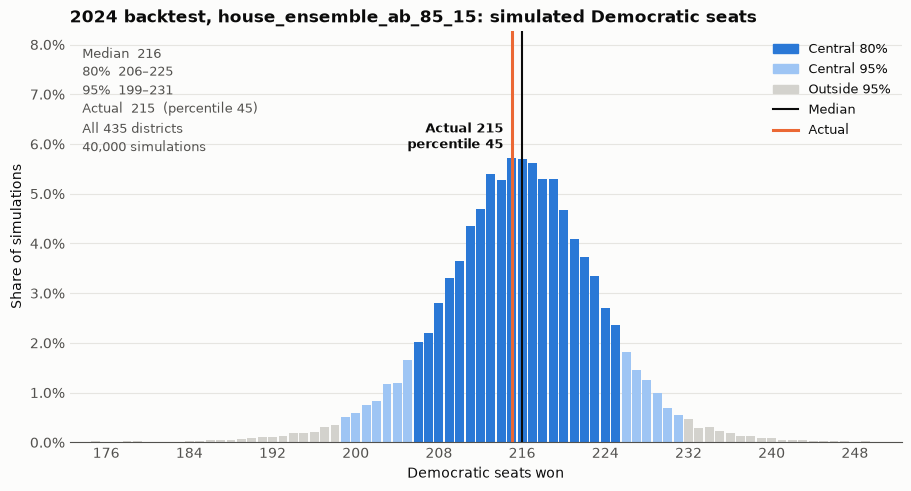

In [21]:
PLOT_YEAR = 2024
PLOT_CONFIG = stage1.HOUSE_ENSEMBLE_AB_85_15

plot_result = calibration[PLOT_CONFIG.name].years[PLOT_YEAR]
fig, ax = simulation.plot_seat_distribution(
    plot_result.panel_dem_seats,
    year=PLOT_YEAR,
    actual_seats=plot_result.panel_actual_dem_seats,
    panel_size=plot_result.panel_size,
    house_size=plot_result.house_size,
    title=f"{PLOT_YEAR} backtest, {PLOT_CONFIG.name}: simulated Democratic seats",
)

In [22]:
# The chart shows exactly the table's numbers
row = calibration_table.loc[(PLOT_CONFIG.name, PLOT_YEAR)]
plotted = {line.get_gid(): line.get_xdata()[0] for line in ax.lines}
assert plotted == {"median": row["median panel_dem_seats"], "actual": row["panel_actual_dem_seats"]}
seats = plot_result.seat_summary()
for level, (lower, upper) in seats["intervals"].items():
    assert row[f"{round(100 * level)}% panel seat interval"] == f"{lower}–{upper}"
assert seats["percentile"] == row["actual-seat percentile"]
assert row["matched panel"] == f"{plot_result.panel_size} of {HOUSE_SEATS}"
print(f"plot matches the table: {row['matched panel']} districts, median {seats['median']}, "
      f"actual {seats['actual']} (percentile {seats['percentile']:.1f})")

plot matches the table: 435 of 435 districts, median 216, actual 215 (percentile 45.4)


### Every backtest election

The same stored draws for both configurations and all three test years. Columns share an x range, so the two configurations compare directly within a year. Each panel is every race with a resolved winner (all 435 in 2020–2024), and the seats are full-House Democratic seats.

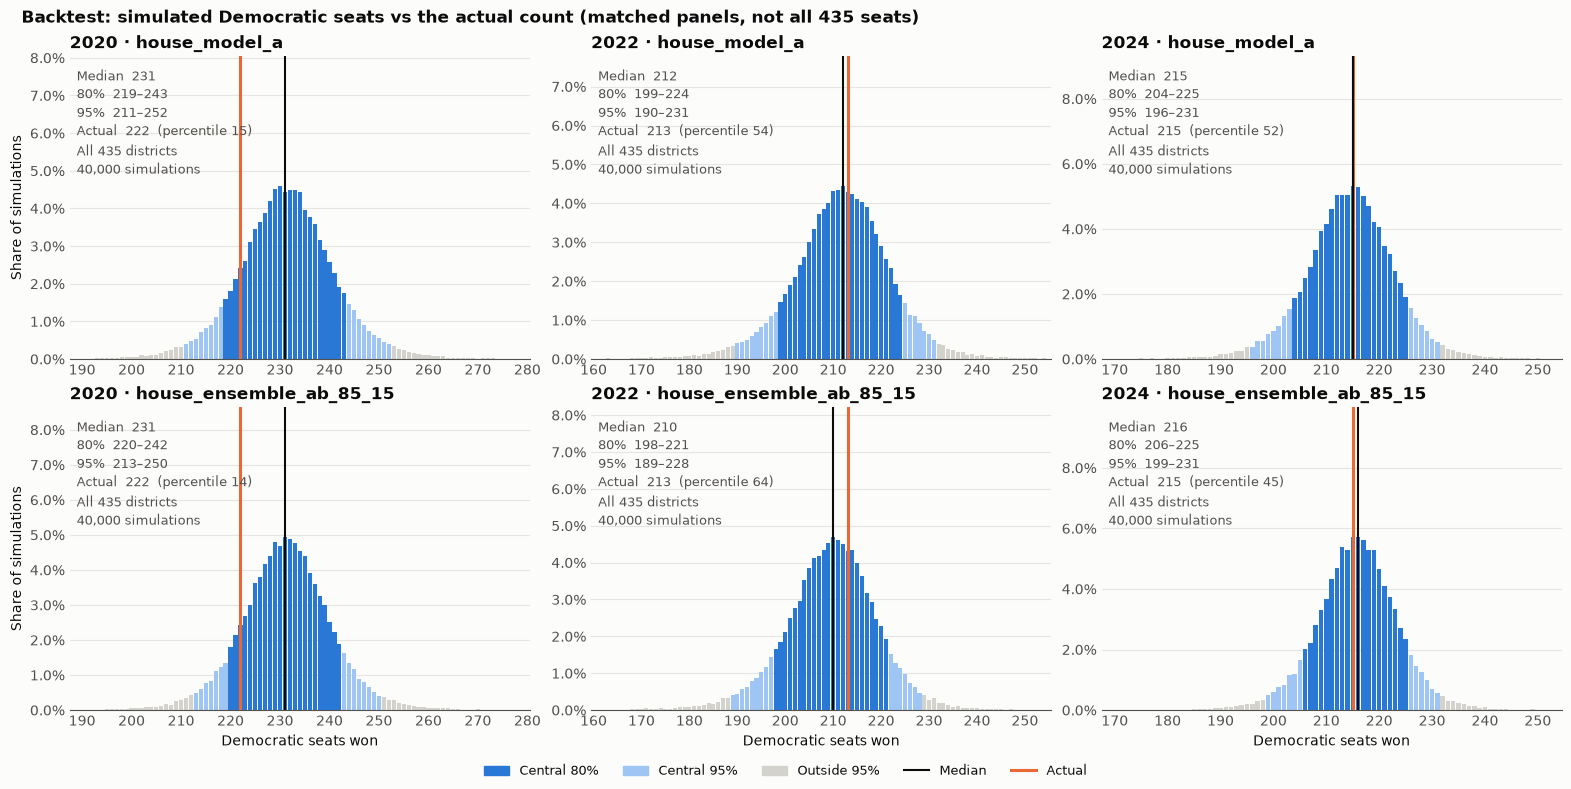

In [23]:
fig, axes = simulation.plot_backtest_seat_distributions(calibration)

**Seat errors.** Each row is one election's simulated median and central 80% / 95% intervals, minus the actual matched-panel count, so 0 is what happened. A row whose intervals sit right of 0 expected more Democratic seats than Democrats won. These are the table's numbers (`seat_summary`), on one axis.

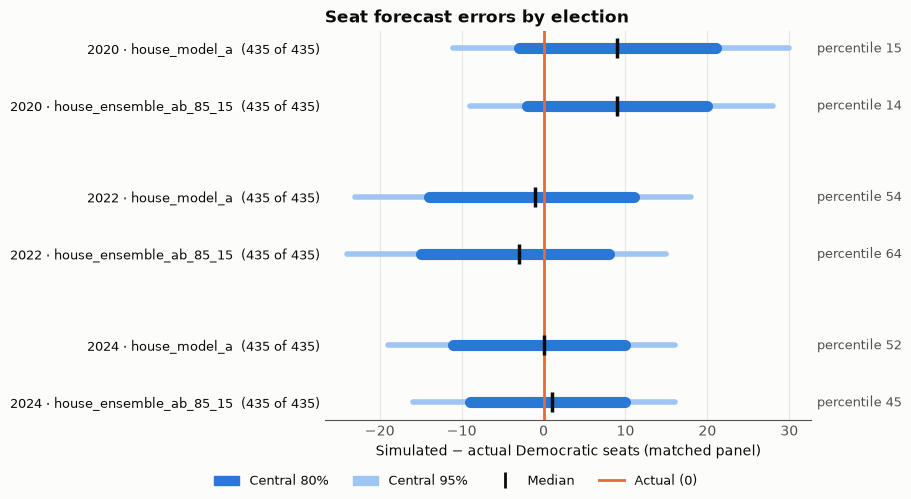

In [24]:
fig, ax = simulation.plot_seat_errors(calibration)

**District reliability.** `Calibration.reliability()` bins each year's resolved races by simulated D win probability (the rule-decided ones fall in the outer bins) (`RELIABILITY_EDGES`: 0–10%, 10–30%, 30–50%, 50–70%, 70–90%, 90–100%) and compares the bin's mean probability (`forecast`) with the share Democrats won (`observed`). The middle four bins hold the races in play, only about 5–30 districts each, so one race moves a bin's observed share by several points. Read them as direction, not proof.

In [25]:
simulation.styled(pd.concat({name: cal.reliability() for name, cal in calibration.items()}, axis=1))

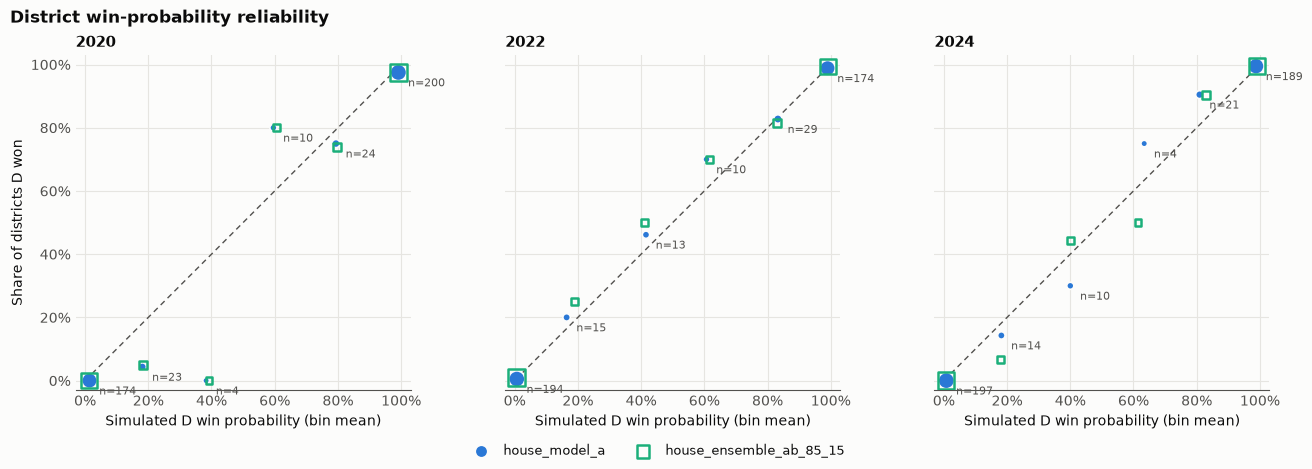

In [26]:
fig, axes = simulation.plot_reliability(calibration)

**The separate 2018 test, same views.** Stage 2 here is fit on 2012–2016 residuals (see *Separate 2018 test*).

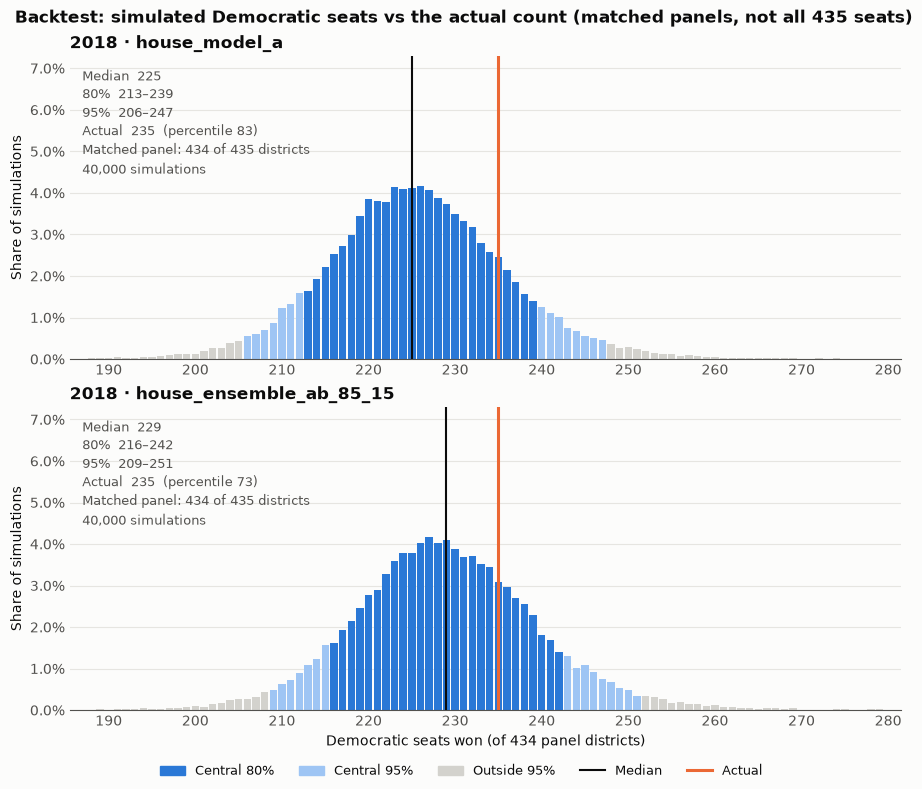

In [27]:
fig, axes = simulation.plot_backtest_seat_distributions(early_calibration)

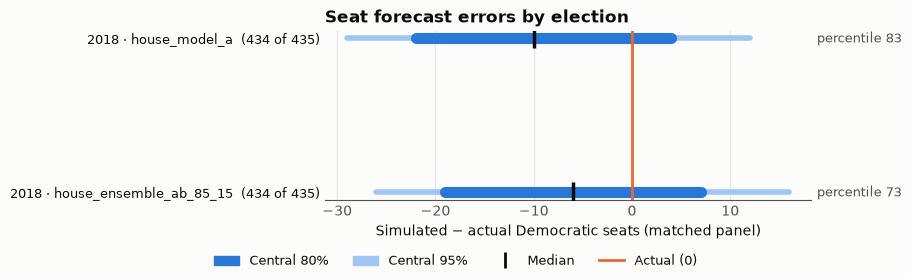

In [28]:
fig, ax = simulation.plot_seat_errors(early_calibration)

### Calls, competitive races, and seats

For every test election (the main 2020–2024 backtest and the separate 2018 test) and both configurations. A race's **call** is its most likely ballot party: D, R, or other (`simulation.call_party`); other is never folded into D or R.

- **Wrong calls:** each resolved race whose call missed the winner, most confident misses first.
- **Competitive stats:** the confusion matrix (called D / R against won D / R; `any other` counts calls or winners outside the two parties), with accuracy, Brier, and coverage. Shown for every resolved race, the `contested` (simulated D-vs-R) ones, `competitive_ex_ante` (|lean + eve generic ballot| ≤ 10, known before the election), and `competitive_ex_post` (|actual margin| ≤ 10). The ex-post subset uses the result, so it describes the misses but could not have been chosen in advance.
- **Seats:** median simulated D seats against the actual count, over each year's resolved races (N of 435). `called D seats` adds up the race calls, which needn't equal the median of the seat draws.

In [29]:
BACKTESTS = {"2018 test": early_calibration, "main": calibration}  # reported side by side, never pooled

wrong_calls = simulation.stack(BACKTESTS, "wrong_calls")
wrong_calls.groupby(["backtest", "config", "year"]).size().unstack("year").fillna(0).astype(int)

year                               2018  2020  2022  2024
backtest  config                                         
2018 test house_ensemble_ab_85_15    19     0     0     0
          house_model_a              20     0     0     0
main      house_ensemble_ab_85_15     0    14    20    10
          house_model_a               0    14    20     9

In [30]:
# Every wrong call
simulation.styled(wrong_calls)

In [31]:
simulation.styled(simulation.stack(BACKTESTS, "competitive_stats"))

In [32]:
simulation.styled(simulation.stack(BACKTESTS, "seats"))

## 5. 2026 forecast: every race

The production forecast for all 435 districts, with the same race handling as the backtest:

- **Lineups** come from the candidate registry, `data/processed/house/candidates_2026.csv`, built by `data-processing/house/candidates_2026.py` from the pinned nominee list and FEC. It has one row per listed general-election candidate, with ballot party, model party, race type and election method.
- **Simulated races:** 417 D-vs-R races, simulated from the ensemble's margins (Model A if the ensemble can't predict one).
- **Rule-decided races:** 5 uncontested D, 4 D vs third party only, 8 D vs D, and 1 R vs R.
- **CA-6:** Kiley, an independent on the ballot, is the Republican proxy for Stage 1. A draw he wins is counted officially as `other`. The `Kiley caucuses R` row below is a separate, optional scenario.
- **Candidates:** a winning party with one candidate on the ballot resolves to that candidate.
  - **Same-party top-two races** (CA-4, 7, 11, 12, 14, 29, 34, 37 and 40) are resolved by `simulation.TopTwoSameParty`.
    - It blends three predictions of the June leader's November margin: the June primary, fundraising and a poll, weighted 60/30/10, or 60/40 without a poll.
    - It names the finalist with p ≥ 0.5. Its probabilities and intervals are shown below.
    - There is no training data, so the weights and the uncertainty are set by hand (`TOP_TWO_*`). Inputs: `data/processed/house/toptwosameparty.csv`.
    - It changes no party outcome or seat count.
  - **Louisiana's all-candidate round** stays unresolved.
- **Draws** come from `np.random.default_rng([SEED, 2026])`, with the error scales of section 2.

In [33]:
FORECAST_YEAR = 2026

# Same-party top-two races (src/house/simulation/top_two.py): which finalist wins. Set by hand, no training data
TOP_TWO_WEIGHTS_WITH_POLL = {"primary": 0.6, "fundraising": 0.3, "poll": 0.1}
TOP_TWO_WEIGHTS_NO_POLL = {"primary": 0.6, "fundraising": 0.4}
TOP_TWO_POINTS_PER_LOG = 4.46  # Model B's fundraising_advantage coefficient (2006-2024 fit), points per log unit
TOP_TWO_BASE_SD = 8.0          # points: the June-to-November shift any race has
TOP_TWO_SPLIT_SD = 0.15        # SD of the leader's share of June voters who backed neither finalist

top_two = simulation.predict_top_two(simulation.load_top_two(), weights_with_poll=TOP_TWO_WEIGHTS_WITH_POLL,
                                     weights_no_poll=TOP_TWO_WEIGHTS_NO_POLL, points_per_log=TOP_TWO_POINTS_PER_LOG,
                                     base_sd=TOP_TWO_BASE_SD, split_sd=TOP_TWO_SPLIT_SD, nu=NU)
RESOLVERS = [simulation.TopTwoSameParty(top_two)]  # names the same-party winner; party outcomes unchanged

fallback_forecast = simulation.stage1_forecast(FALLBACK_CONFIG, predictors=predictors, targets=targets)
point_2026 = simulation.attach_predictions(simulation.races_2026(candidates), forecast.predictions,
                                           primary_source=CONFIG.name, fallback=fallback_forecast.predictions)
draws_2026 = simulation.simulate_races(point_2026, ERROR_SCALE, NU, N_SIMS,
                                       np.random.default_rng([SEED, FORECAST_YEAR]), resolvers=RESOLVERS)
forecast_2026 = simulation.forecast_table(draws_2026, candidates, resolvers=RESOLVERS)
forecast_2026.groupby(["treatment", "race_type", "prediction_source"]).size().rename("races")

treatment    race_type        prediction_source      
fixed        dem_uncontested  fixed                        5
same_party   dem_vs_dem       same_party                   8
             gop_vs_gop       same_party                   1
simulated    dr               house_ensemble_ab_85_15    408
             dr_jungle        house_ensemble_ab_85_15      6
             dr_rcv           house_ensemble_ab_85_15      3
third_party  dem_vs_3p        third_party                  4
Name: races, dtype: int64

In [34]:
# Seats by ballot party: the official count, and the optional caucus scenario
KILEY_CAUCUSES_R = {(2026, "CA", 6): simulation.GOP}  # an independent's win counted for the party he'd caucus with
SEAT_SCENARIOS = {"official": None, "Kiley caucuses R": KILEY_CAUCUSES_R}
simulation.styled(simulation.seat_table(draws_2026, SEAT_SCENARIOS))

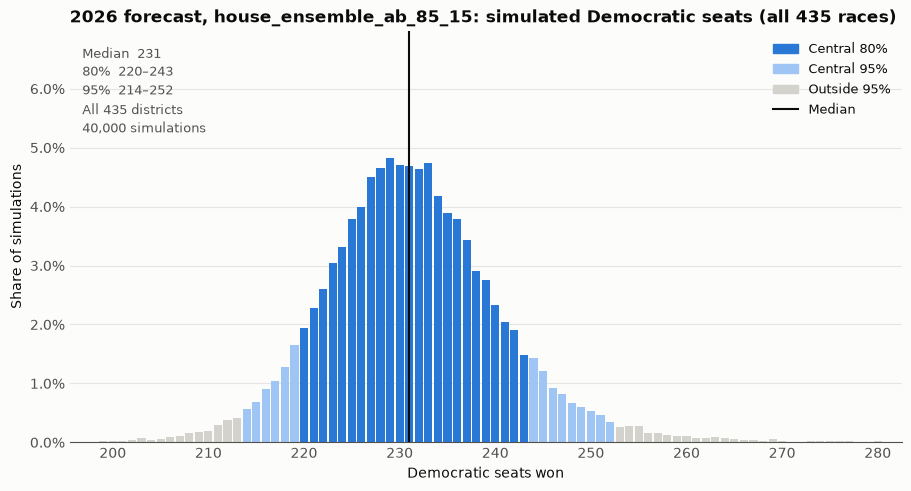

In [35]:
fig, ax = simulation.plot_seat_distribution(
    draws_2026.seats(simulation.DEM),
    year=FORECAST_YEAR,
    actual_seats=None,
    panel_size=HOUSE_SEATS,
    house_size=HOUSE_SEATS,
    title=f"2026 forecast, {CONFIG.name}: simulated Democratic seats (all 435 races)",
)

In [36]:
# The closest races and every race decided by rule
close = forecast_2026[forecast_2026[["p_dem", "p_gop", "p_other"]].max(axis=1) < 0.9]
display(Markdown(f"**{len(close)} races where no party wins 90% of draws**"))
display(simulation.styled(close.sort_values("p_dem")))
display(Markdown("**Races decided by rule** (no Stage 1 margin)"))
simulation.styled(forecast_2026[forecast_2026["treatment"] != "simulated"])

**54 races where no party wins 90% of draws**

,year,state,district,race_type,election_method,treatment,prediction_source,prediction,p_dem,p_gop,p_other,predicted_party,predicted_candidate,candidate_status
97,2026,FL,11,dr,standard,simulated,house_ensemble_ab_85_15,-8.1,10.2%,89.8%,0.0%,R,Joe Strada,resolved
90,2026,FL,4,dr,standard,simulated,house_ensemble_ab_85_15,-7.5,12.0%,88.0%,0.0%,R,Aaron Bean,resolved
273,2026,NY,2,dr,standard,simulated,house_ensemble_ab_85_15,-7.4,12.2%,87.8%,0.0%,R,Andrew Garbarino,resolved
113,2026,FL,27,dr,standard,simulated,house_ensemble_ab_85_15,-7.3,12.4%,87.6%,0.0%,R,María Elvira Salazar,resolved
99,2026,FL,13,dr,standard,simulated,house_ensemble_ab_85_15,-7.3,12.8%,87.2%,0.0%,R,Anna Paulina Luna,resolved
254,2026,NJ,2,dr,standard,simulated,house_ensemble_ab_85_15,-6.9,13.9%,86.1%,0.0%,R,Jeff Van Drew,resolved
418,2026,WA,5,dr,top_two,simulated,house_ensemble_ab_85_15,-6.5,15.1%,84.9%,0.0%,R,Michael Baumgartner,resolved
211,2026,MN,1,dr,standard,simulated,house_ensemble_ab_85_15,-6.4,15.3%,84.7%,0.0%,R,Brad Finstad,resolved
172,2026,KY,6,dr,standard,simulated,house_ensemble_ab_85_15,-6.1,16.6%,83.4%,0.0%,R,Ralph Alvarado,resolved
269,2026,NV,2,dr,standard,simulated,house_ensemble_ab_85_15,-6.1,17.0%,83.0%,0.0%,R,David Flippo,resolved


**Races decided by rule** (no Stage 1 margin)

,year,state,district,race_type,election_method,treatment,prediction_source,prediction,p_dem,p_gop,p_other,predicted_party,predicted_candidate,candidate_status
14,2026,AZ,3,dem_vs_3p,standard,third_party,third_party,+nan,99.5%,0.0%,0.5%,D,Yassamin Ansari,resolved
24,2026,CA,4,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,Mike Thompson,resolved_by_TopTwoSameParty
27,2026,CA,7,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,Mai Vang,resolved_by_TopTwoSameParty
31,2026,CA,11,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,Scott Wiener,resolved_by_TopTwoSameParty
32,2026,CA,12,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,Lateefah Simon,resolved_by_TopTwoSameParty
34,2026,CA,14,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,Aisha Wahab,resolved_by_TopTwoSameParty
49,2026,CA,29,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,Luz Rivas,resolved_by_TopTwoSameParty
54,2026,CA,34,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,Jimmy Gomez,resolved_by_TopTwoSameParty
57,2026,CA,37,dem_vs_dem,top_two,same_party,same_party,+nan,100.0%,0.0%,0.0%,D,Sydney Kamlager-Dove,resolved_by_TopTwoSameParty
60,2026,CA,40,gop_vs_gop,top_two,same_party,same_party,+nan,0.0%,100.0%,0.0%,R,Ken Calvert,resolved_by_TopTwoSameParty


In [37]:
# Candidate resolution: unresolved winners, with the reason (resolved_by_* rows were named by a resolver)
display(forecast_2026["candidate_status"].value_counts().rename("races"))
forecast_2026.loc[~forecast_2026["candidate_status"].str.startswith("resolved"),
                  [*hr.KEY, "race_type", "election_method", "predicted_party", "candidate_status"]]

candidate_status
resolved                       420
resolved_by_TopTwoSameParty      9
several_R_candidates             5
several_D_candidates             1
Name: races, dtype: int64

,year,state,district,race_type,election_method,predicted_party,candidate_status
173,2026,LA,1,dr_jungle,jungle,R,several_R_candidates
174,2026,LA,2,dr_jungle,jungle,D,several_D_candidates
175,2026,LA,3,dr_jungle,jungle,R,several_R_candidates
176,2026,LA,4,dr_jungle,jungle,R,several_R_candidates
177,2026,LA,5,dr_jungle,jungle,R,several_R_candidates
178,2026,LA,6,dr_jungle,jungle,R,several_R_candidates


In [38]:
# Same-party races: each component margin (leader over runner-up, points), the blend, its 80% interval, and P(win)
picked = forecast_2026.merge(top_two, on=hr.KEY)
favorite = picked["leader"].where(picked["p_leader"] >= 0.5, picked["runner_up"])
assert (picked["predicted_candidate"] == favorite).all() and len(picked) == len(top_two)  # the forecast names them
top_two[[*hr.KEY, "leader", "runner_up", "margin_primary", "margin_fundraising", "margin_poll", "weights",
         "uncommitted_share", "mean", "sd", "interval_80_low", "interval_80_high", "p_leader", "p_runner_up"]].round(2)

,year,state,district,leader,runner_up,margin_primary,margin_fundraising,margin_poll,weights,uncommitted_share,mean,sd,interval_80_low,interval_80_high,p_leader,p_runner_up
0,2026,CA,4,Mike Thompson,Eric Jones,29.65,-0.35,NaN,"primary 0.6, fundraising 0.4",36.80,17.65,13.63,2.06,33.24,0.92,0.08
1,2026,CA,7,Mai Vang,Doris Matsui,3.55,1.81,-11.36,"primary 0.6, fundraising 0.3, poll 0.1",39.68,1.54,14.34,-14.86,17.94,0.55,0.45
2,2026,CA,11,Scott Wiener,Connie Chan,15.64,4.24,7.37,"primary 0.6, fundraising 0.3, poll 0.1",29.58,11.39,11.95,-2.27,25.05,0.86,0.14
3,2026,CA,12,Lateefah Simon,Jamie Joyce,68.75,13.28,NaN,"primary 0.6, fundraising 0.4",0.15,46.56,8.00,37.41,55.71,1.00,0.00
4,2026,CA,14,Aisha Wahab,Melissa Hernandez,38.06,-3.37,NaN,"primary 0.6, fundraising 0.4",44.54,21.48,15.57,3.68,39.29,0.93,0.07
5,2026,CA,29,Luz Rivas,Angelica Dueñas,34.37,7.93,NaN,"primary 0.6, fundraising 0.4",24.02,23.79,10.77,11.48,36.10,0.98,0.02
6,2026,CA,34,Jimmy Gomez,Angela Gonzales-Torres,19.94,2.08,-6.25,"primary 0.6, fundraising 0.3, poll 0.1",23.32,11.96,10.63,-0.19,24.11,0.90,0.10
7,2026,CA,37,Sydney Kamlager-Dove,Samantha Mota,65.08,23.90,NaN,"primary 0.6, fundraising 0.4",33.15,48.61,12.76,34.02,63.20,1.00,0.00
8,2026,CA,40,Ken Calvert,Young Kim,25.69,-3.36,NaN,"primary 0.6, fundraising 0.4",44.48,14.07,15.56,-3.71,31.86,0.85,0.15


In [39]:
# Checks: one outcome per race and draw, the overrides, no invented margins, ballot identities, reproducibility
print(simulation.check_forecast(forecast_2026, draws_2026, candidates, house_size=HOUSE_SEATS))
again = simulation.simulate_races(point_2026, ERROR_SCALE, NU, N_SIMS, np.random.default_rng([SEED, FORECAST_YEAR]),
                                  resolvers=RESOLVERS)
print(simulation.check_same_draws(again, draws_2026))

forecast checks passed: 40,000 draws x 435 races


reproducibility check passed: identical draws


In [40]:
# The production submission: the congress-track template's House rows, from this forecast (H0, CONFIG)
TRACK_OUTPUT_PATH = ROOT / "data/processed/house/congress_track_house_2026.csv"

track = simulation.track_table(forecast_2026, top_two, fec_slots=pd.read_csv(ROOT / "data/processed/house_fec.csv"),
                               template=pd.read_csv(simulation.TRACK_TEMPLATE_PATH))
track.to_csv(TRACK_OUTPUT_PATH, index=False)
display(Markdown(f"**{len(track)} House rows -> `{TRACK_OUTPUT_PATH.relative_to(ROOT)}`**"))
display(track["predicted_winner_party"].value_counts().rename("seats called"))
track.sort_values("win_probability").head(15)

**435 House rows -> `data/processed/house/congress_track_house_2026.csv`**

predicted_winner_party
D    227
R    208
Name: seats called, dtype: int64

,race_id,chamber,predicted_winner_party,candidate_name,win_probability
402,VA-01,House,D,Shannon Taylor,0.502000
394,TX-35,House,R,Carlos De La Cruz,0.504075
201,MI-04,House,R,Bill Huizenga,0.506125
108,FL-22,House,R,Casey Askar,0.527075
333,PA-10,House,D,Janelle Stelson,0.531800
132,IA-02,House,R,Joe Mitchell,0.538450
424,WI-01,House,D,Mitchell Berman,0.544600
27,CA-07,House,D,Mai Vang,0.552381
233,NC-01,House,D,Don Davis,0.563350
197,ME-02,House,R,Paul LePage,0.565275
